<a href="https://colab.research.google.com/github/varshitfauzdar/AIH_Lab_work/blob/main/Lab6_AIH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q kagglehub
import kagglehub
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
import kagglehub

path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset downloaded to:")
print(path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset downloaded to:
/kaggle/input/chest-xray-pneumonia


In [4]:
print(os.listdir(path))
dataset_path = os.path.join(path, "chest_xray")

print(os.listdir(dataset_path))

['chest_xray']
['chest_xray', '__MACOSX', 'val', 'test', 'train']


In [5]:
train_path = os.path.join(dataset_path, "train")

print(os.listdir(train_path))

['PNEUMONIA', 'NORMAL']


In [6]:
normal_path = os.path.join(train_path, "NORMAL")
pneumonia_path = os.path.join(train_path, "PNEUMONIA")

normal_images = os.listdir(normal_path)
pneumonia_images = os.listdir(pneumonia_path)

print("Normal images:", len(normal_images))
print("Pneumonia images:", len(pneumonia_images))

Normal images: 1341
Pneumonia images: 3875


Image size: (1336, 1128)
Image mode: L


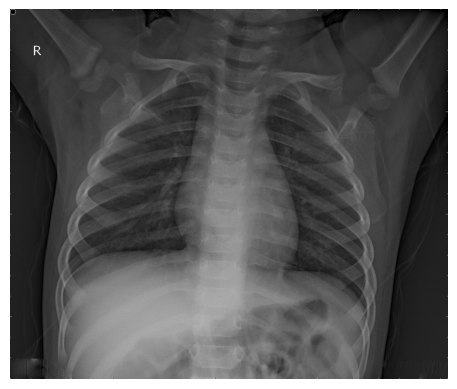

In [7]:
img_path = os.path.join(normal_path, normal_images[0])

img = Image.open(img_path)

print("Image size:", img.size)
print("Image mode:", img.mode)

plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

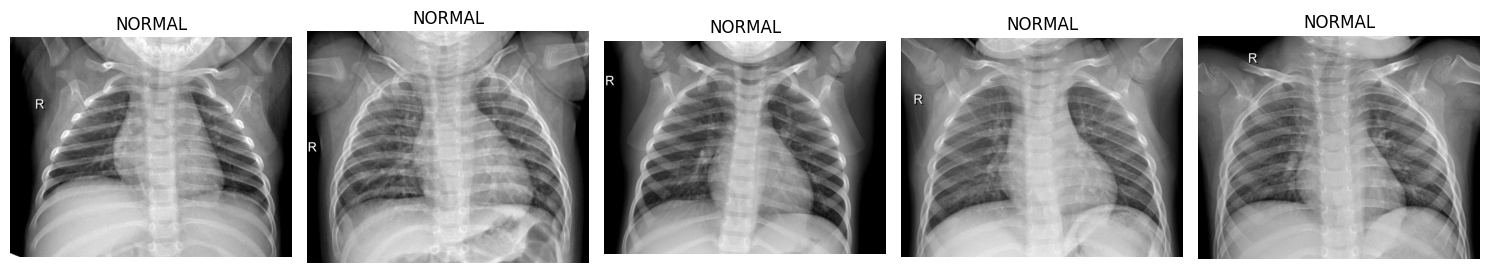

In [8]:
random_normal = random.sample(normal_images, 5)

plt.figure(figsize=(15, 8))

for i, filename in enumerate(random_normal):
    img_path = os.path.join(normal_path, filename)
    img = Image.open(img_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title("NORMAL")
    plt.axis("off")

plt.tight_layout()
plt.show()

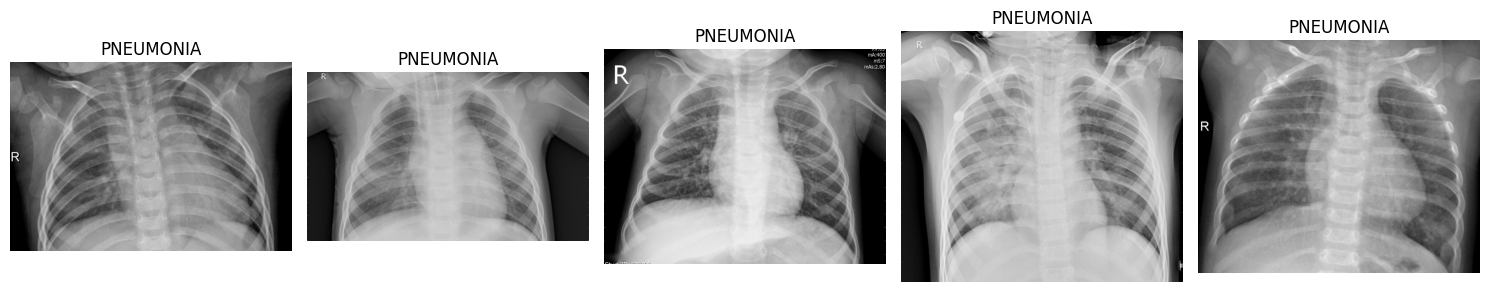

In [9]:
random_pneumonia = random.sample(pneumonia_images, 5)

plt.figure(figsize=(15, 8))

for i, filename in enumerate(random_pneumonia):
    img_path = os.path.join(pneumonia_path, filename)
    img = Image.open(img_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title("PNEUMONIA")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
!pip install -q opencv-python
import cv2
import numpy as np
import pandas as pd
import os

from skimage.feature import hog, local_binary_pattern
from skimage.feature import graycomatrix, graycoprops

from sklearn.model_selection import train_test_split

In [11]:
IMG_SIZE = 128

print("Image size:", IMG_SIZE, "x", IMG_SIZE)

Image size: 128 x 128


In [12]:
def preprocess_image(image_path):

    # Read image
    image = cv2.imread(image_path)

    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Resize
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))

    # Normalize pixels between 0 and 1
    normalized = gray / 255.0

    return normalized

In [13]:
sample_path = os.path.join(normal_path, normal_images[0])

processed_image = preprocess_image(sample_path)

print("Shape:", processed_image.shape)
print("Minimum:", processed_image.min())
print("Maximum:", processed_image.max())

Shape: (128, 128)
Minimum: 0.0
Maximum: 0.9921568627450981


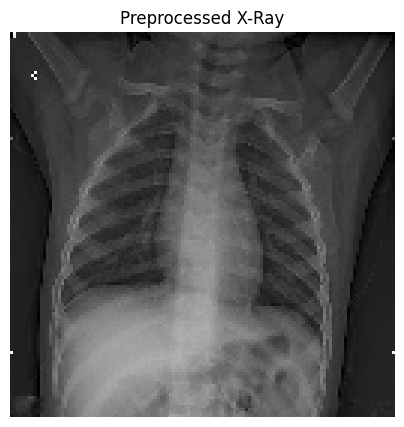

In [14]:
plt.figure(figsize=(5, 5))

plt.imshow(processed_image, cmap="gray")
plt.title("Preprocessed X-Ray")
plt.axis("off")

plt.show()

In [15]:
def extract_hog(image):

    features = hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys'
    )

    return features

In [16]:
hog_features = extract_hog(processed_image)

print("HOG feature vector shape:", hog_features.shape)
print("Number of HOG features:", len(hog_features))

HOG feature vector shape: (8100,)
Number of HOG features: 8100


In [17]:
def extract_lbp(image):

    # Convert normalized image back to 0-255
    image_uint8 = (image * 255).astype(np.uint8)

    radius = 1
    n_points = 8 * radius

    lbp = local_binary_pattern(
        image_uint8,
        n_points,
        radius,
        method='uniform'
    )

    # Create histogram
    n_bins = n_points + 2

    histogram, _ = np.histogram(
        lbp.ravel(),
        bins=n_bins,
        range=(0, n_bins),
        density=True
    )

    return histogram

In [18]:
lbp_features = extract_lbp(processed_image)

print("LBP feature vector shape:", lbp_features.shape)
print("LBP features:", lbp_features)

LBP feature vector shape: (10,)
LBP features: [0.06726074 0.08068848 0.05621338 0.10540771 0.14807129 0.13879395
 0.07611084 0.08520508 0.09844971 0.14379883]


In [19]:
def extract_glcm(image):

    # Convert image to integer grayscale
    image_uint8 = (image * 255).astype(np.uint8)

    # Reduce gray levels to make GLCM computationally manageable
    image_quantized = (image_uint8 // 32).astype(np.uint8)

    glcm = graycomatrix(
        image_quantized,
        distances=[1],
        angles=[0],
        levels=8,
        symmetric=True,
        normed=True
    )

    features = [
        graycoprops(glcm, 'contrast')[0, 0],
        graycoprops(glcm, 'dissimilarity')[0, 0],
        graycoprops(glcm, 'homogeneity')[0, 0],
        graycoprops(glcm, 'energy')[0, 0],
        graycoprops(glcm, 'correlation')[0, 0]
    ]

    return np.array(features)

In [20]:
glcm_features = extract_glcm(processed_image)

print("GLCM feature vector:")
print(glcm_features)

print("Number of GLCM features:", len(glcm_features))

GLCM feature vector:
[0.24243356 0.20589321 0.89985871 0.42588858 0.92136034]
Number of GLCM features: 5


In [21]:
combined_features = np.concatenate([
    hog_features,
    lbp_features,
    glcm_features
])

print("Combined feature vector shape:", combined_features.shape)

Combined feature vector shape: (8115,)


In [22]:
from glob import glob

normal_files = glob(os.path.join(dataset_path, "**", "NORMAL", "*.jpeg"), recursive=True)
pneumonia_files = glob(os.path.join(dataset_path, "**", "PNEUMONIA", "*.jpeg"), recursive=True)

print("Normal images:", len(normal_files))
print("Pneumonia images:", len(pneumonia_files))
print("Total images:", len(normal_files) + len(pneumonia_files))

Normal images: 3166
Pneumonia images: 8546
Total images: 11712


In [23]:
image_paths = normal_files + pneumonia_files

labels = (
    [0] * len(normal_files) +
    [1] * len(pneumonia_files)
)

print("Total image paths:", len(image_paths))
print("Total labels:", len(labels))

Total image paths: 11712
Total labels: 11712


In [24]:
from collections import Counter

print(Counter(labels))

Counter({1: 8546, 0: 3166})


In [25]:
combined = list(zip(image_paths, labels))

random.seed(42)
random.shuffle(combined)

image_paths, labels = zip(*combined)

image_paths = np.array(image_paths)
labels = np.array(labels)

print("Dataset shuffled successfully.")

Dataset shuffled successfully.


In [26]:
X_train_paths, X_temp_paths, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

print("Training:", len(X_train_paths))
print("Temporary:", len(X_temp_paths))

Training: 8198
Temporary: 3514


In [27]:
X_val_paths, X_test_paths, y_val, y_test = train_test_split(
    X_temp_paths,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train_paths))
print("Validation images:", len(X_val_paths))
print("Testing images:", len(X_test_paths))

Training images: 8198
Validation images: 1757
Testing images: 1757


In [28]:
print("Training distribution:")
print(Counter(y_train))

print("\nValidation distribution:")
print(Counter(y_val))

print("\nTesting distribution:")
print(Counter(y_test))

Training distribution:
Counter({np.int64(1): 5982, np.int64(0): 2216})

Validation distribution:
Counter({np.int64(1): 1282, np.int64(0): 475})

Testing distribution:
Counter({np.int64(1): 1282, np.int64(0): 475})


In [29]:
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Number of Images": [
        len(X_train_paths),
        len(X_val_paths),
        len(X_test_paths)
    ],
    "Percentage": [
        len(X_train_paths) / len(image_paths) * 100,
        len(X_val_paths) / len(image_paths) * 100,
        len(X_test_paths) / len(image_paths) * 100
    ]
})

split_summary

,Dataset,Number of Images,Percentage
0,Training,8198,69.996585
1,Validation,1757,15.001708
2,Testing,1757,15.001708


In [30]:
def load_images(image_paths):

    images = []

    for path in image_paths:
        image = preprocess_image(path)
        images.append(image)

    return np.array(images, dtype=np.float32)

X_train = load_images(X_train_paths)
X_val = load_images(X_val_paths)
X_test = load_images(X_test_paths)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (8198, 128, 128)
X_val shape: (1757, 128, 128)
X_test shape: (1757, 128, 128)


In [31]:
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (8198, 128, 128, 1)
X_val: (1757, 128, 128, 1)
X_test: (1757, 128, 128, 1)


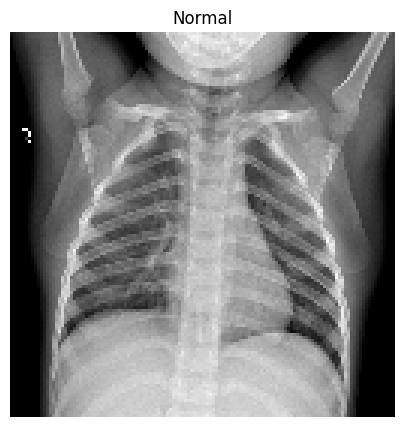

In [32]:
plt.figure(figsize=(5, 5))

plt.imshow(X_train[0].squeeze(), cmap="gray")
plt.title(
    "Pneumonia" if y_train[0] == 1 else "Normal"
)
plt.axis("off")

plt.show()

In [33]:
!pip install -q tensorflow
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [34]:
model = models.Sequential([

    # Input layer
    layers.Input(shape=(128, 128, 1)),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),

    # Prevent overfitting
    layers.Dropout(0.5),

    # Binary classification
    layers.Dense(1, activation='sigmoid')
])



In [35]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,233 (16.35 MB)

 Trainable params: 4,287,233 (16.35 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [37]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:")
print(class_weights)

Class weights:
{np.int64(0): np.float64(1.8497292418772564), np.int64(1): np.float64(0.6852223336676697)}


In [38]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [39]:
history = model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=20,
    batch_size=32,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 28s 57ms/step - accuracy: 0.8884 - auc: 0.9563 - loss: 0.2695 - precision: 0.9561 - recall: 0.8878 - val_accuracy: 0.9414 - val_auc: 0.9897 - val_loss: 0.1428 - val_precision: 0.9828 - val_recall: 0.9360 - learning_rate: 0.0010
Epoch 2/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9445 - auc: 0.9847 - loss: 0.1541 - precision: 0.9814 - recall: 0.9418 - val_accuracy: 0.9596 - val_auc: 0.9936 - val_loss: 0.0979 - val_precision: 0.9802 - val_recall: 0.9641 - learning_rate: 0.0010
Epoch 3/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9504 - auc: 0.9888 - loss: 0.1322 - precision: 0.9829 - recall: 0.9485 - val_accuracy: 0.9607 - val_auc: 0.9939 - val_loss: 0.1000 - val_precision: 0.9848 - val_recall: 0.9610 - learning_rate: 0.0010
Epoch 4/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9589 - auc: 0.9931 - loss: 0.1040 - precision: 0.9847 - recall: 0.9585 - val_accuracy: 0.9676 - val_auc: 0.9951 - val_loss: 0.0795 

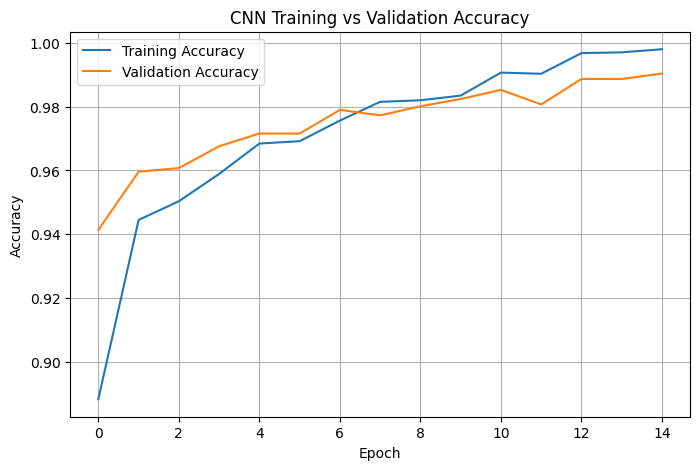

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Training vs Validation Accuracy')
plt.legend()
plt.grid()

plt.show()

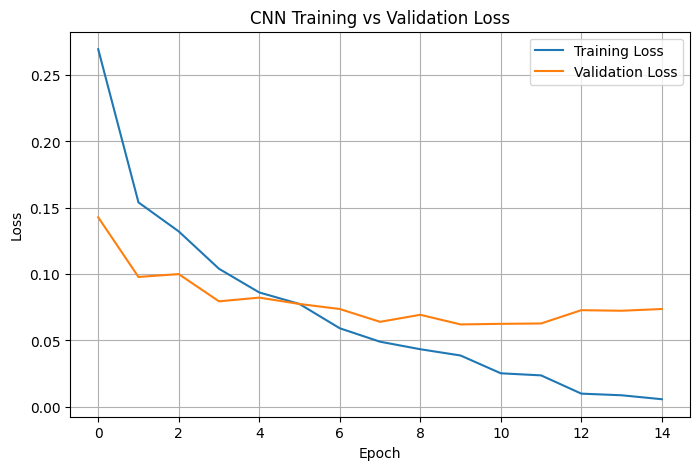

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN Training vs Validation Loss')
plt.legend()
plt.grid()

plt.show()

In [42]:
test_results = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(test_results)

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9818 - auc: 0.9982 - loss: 0.0496 - precision: 0.9929 - recall: 0.9821
[0.04962950199842453, 0.9817871451377869, 0.9929022192955017, 0.9820592999458313, 0.9981902837753296]


In [43]:
y_pred_prob = model.predict(X_test)

print("Prediction shape:", y_pred_prob.shape)
print(y_pred_prob[:10])

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
Prediction shape: (1757, 1)
[[9.9999988e-01]
 [1.4140967e-07]
 [9.9999845e-01]
 [1.0000000e+00]
 [9.9999964e-01]
 [9.9999988e-01]
 [1.0000000e+00]
 [9.9293548e-01]
 [3.5513344e-04]
 [3.2751861e-05]]


In [44]:
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

print("Predicted classes:")
print(y_pred[:20])

Predicted classes:
[1 0 1 1 1 1 1 1 0 0 0 0 1 0 1 0 1 1 1 1]


In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [46]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

auroc = roc_auc_score(y_test, y_pred_prob.ravel())

In [47]:
print("CNN Performance")
print("----------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"AUROC     : {auroc:.4f}")

CNN Performance
----------------------
Accuracy  : 0.9818
Precision : 0.9929
Recall    : 0.9821
F1-score  : 0.9875
AUROC     : 0.9980


In [48]:
metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUROC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        auroc
    ]
})

metrics_df

,Metric,Score
0,Accuracy,0.981787
1,Precision,0.992902
2,Recall,0.982059
3,F1-score,0.987451
4,AUROC,0.998049


In [49]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 466    9]
 [  23 1259]]


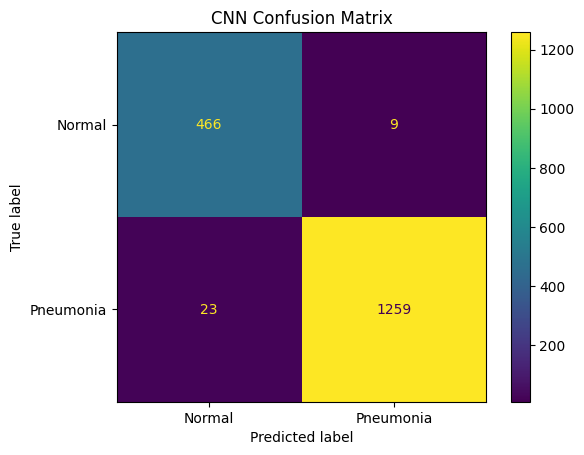

In [50]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot()

plt.title("CNN Confusion Matrix")
plt.show()

In [51]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Pneumonia"]
    )
)
tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

print(f"Specificity: {specificity:.4f}")

              precision    recall  f1-score   support

      Normal       0.95      0.98      0.97       475
   Pneumonia       0.99      0.98      0.99      1282

    accuracy                           0.98      1757
   macro avg       0.97      0.98      0.98      1757
weighted avg       0.98      0.98      0.98      1757

Specificity: 0.9811


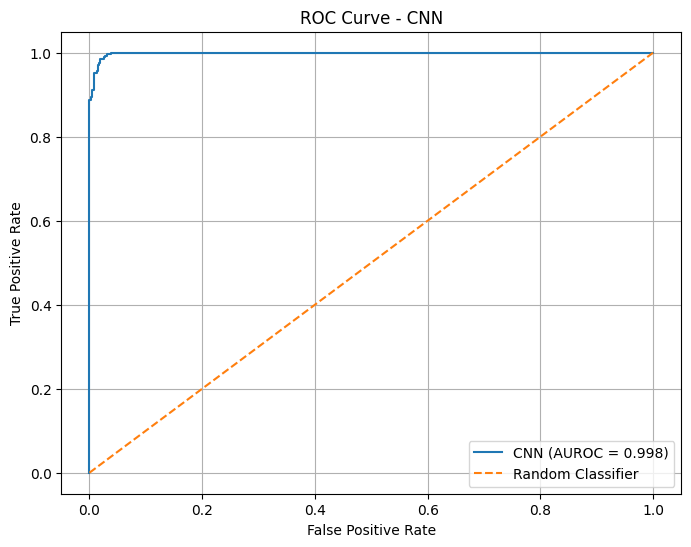

In [52]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_prob.ravel()
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"CNN (AUROC = {auroc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - CNN")
plt.legend()
plt.grid()

plt.show()

In [53]:
misclassified_indices = np.where(y_test != y_pred)[0]

print(
    "Number of misclassified images:",
    len(misclassified_indices)
)

Number of misclassified images: 32


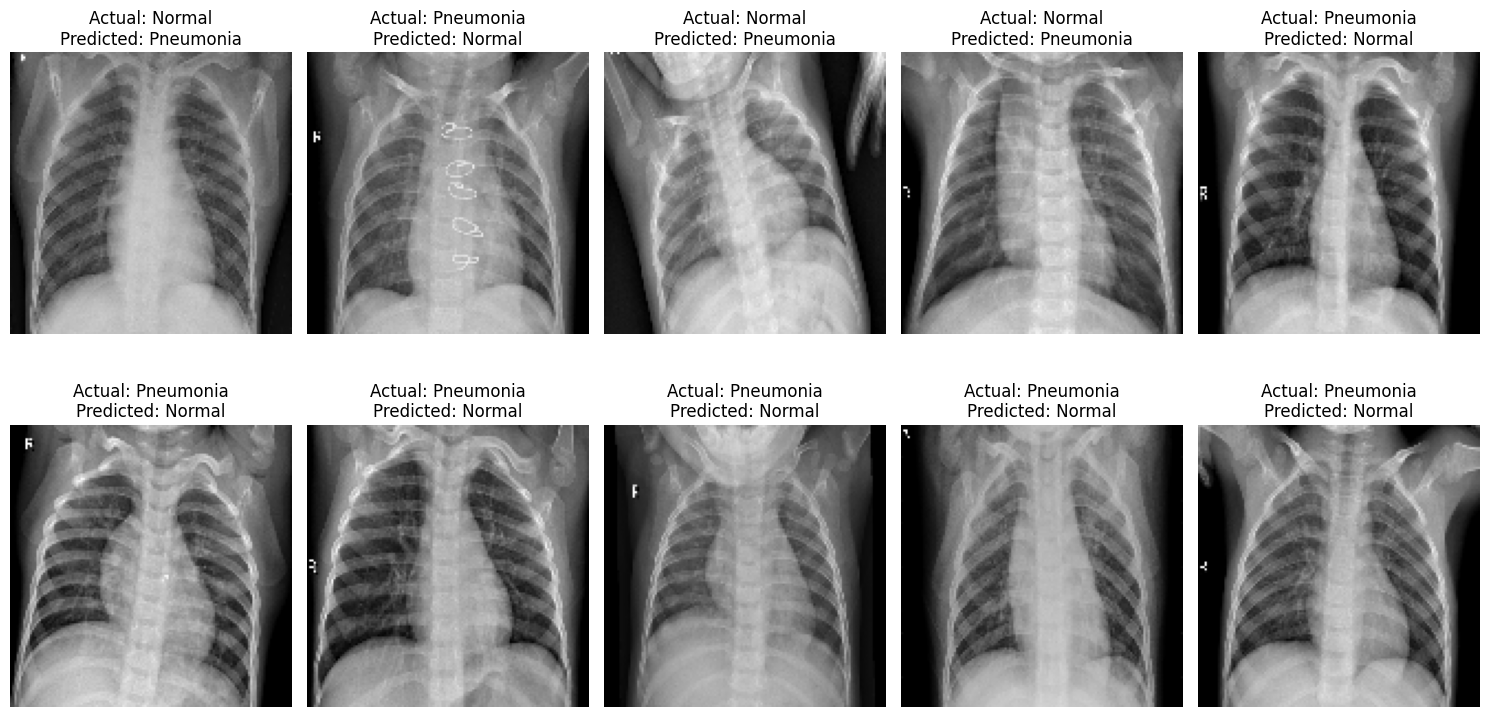

In [54]:
num_images = min(10, len(misclassified_indices))

plt.figure(figsize=(15, 8))

for i in range(num_images):

    idx = misclassified_indices[i]

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[idx].squeeze(),
        cmap="gray"
    )

    actual = "Pneumonia" if y_test[idx] == 1 else "Normal"
    predicted = "Pneumonia" if y_pred[idx] == 1 else "Normal"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [55]:
def build_cnn(
    filters1=32,
    filters2=64,
    filters3=128,
    dropout_rate=0.5,
    learning_rate=0.001
):

    model = models.Sequential([

        layers.Input(shape=(128, 128, 1)),

        # Block 1
        layers.Conv2D(filters1, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Block 2
        layers.Conv2D(filters2, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Block 3
        layers.Conv2D(filters3, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation='relu'),
        layers.Dropout(dropout_rate),

        layers.Dense(1, activation='sigmoid')
    ])

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall'),
            tf.keras.metrics.AUC(name='auc')
        ]
    )

    return model

In [56]:
configs = [
    {
        "name": "Baseline",
        "filters1": 32,
        "filters2": 64,
        "filters3": 128,
        "dropout_rate": 0.5,
        "learning_rate": 0.001,
        "batch_size": 32
    },

    {
        "name": "Lower Dropout",
        "filters1": 32,
        "filters2": 64,
        "filters3": 128,
        "dropout_rate": 0.3,
        "learning_rate": 0.001,
        "batch_size": 32
    },

    {
        "name": "Lower Learning Rate",
        "filters1": 32,
        "filters2": 64,
        "filters3": 128,
        "dropout_rate": 0.5,
        "learning_rate": 0.0001,
        "batch_size": 32
    }
]

print("Number of configurations:", len(configs))

Number of configurations: 3


In [57]:
results = []

for config in configs:

    print("\n" + "=" * 50)
    print("Training:", config["name"])
    print("=" * 50)

    tuned_model = build_cnn(
        filters1=config["filters1"],
        filters2=config["filters2"],
        filters3=config["filters3"],
        dropout_rate=config["dropout_rate"],
        learning_rate=config["learning_rate"]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )

    history_tuned = tuned_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=config["batch_size"],
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=1
    )

    # Evaluate on validation set
    val_results = tuned_model.evaluate(
        X_val,
        y_val,
        verbose=0
    )

    results.append({
        "Configuration": config["name"],
        "Validation Accuracy": val_results[1],
        "Validation Precision": val_results[2],
        "Validation Recall": val_results[3],
        "Validation AUROC": val_results[4]
    })


Training: Baseline
Epoch 1/10
257/257 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.8634 - auc: 0.9475 - loss: 0.2956 - precision: 0.9502 - recall: 0.8577 - val_accuracy: 0.9328 - val_auc: 0.9884 - val_loss: 0.1894 - val_precision: 0.9858 - val_recall: 0.9212
Epoch 2/10
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9316 - auc: 0.9791 - loss: 0.1837 - precision: 0.9725 - recall: 0.9326 - val_accuracy: 0.9567 - val_auc: 0.9896 - val_loss: 0.1152 - val_precision: 0.9660 - val_recall: 0.9750
Epoch 3/10
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9444 - auc: 0.9851 - loss: 0.1524 - precision: 0.9784 - recall: 0.9447 - val_accuracy: 0.9624 - val_auc: 0.9926 - val_loss: 0.1239 - val_precision: 0.9743 - val_recall: 0.9743
Epoch 4/10
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9443 - auc: 0.9868 - loss: 0.1434 - precision: 0.9795 - recall: 0.9433 - val_accuracy: 0.9425 - val_auc: 0.9932 - val_loss: 0.1394 - val_precision: 0.9900 - val_recall: 0.9306
Epoch 5

In [58]:
results_df = pd.DataFrame(results)

results_df

,Configuration,Validation Accuracy,Validation Precision,Validation Recall,Validation AUROC
0,Baseline,0.971542,0.981250,0.979719,0.995154
1,Lower Dropout,0.981787,0.986760,0.988300,0.995891
2,Lower Learning Rate,0.962436,0.979495,0.968799,0.993070


In [59]:
best_index = results_df["Validation AUROC"].idxmax()

best_config_name = results_df.loc[
    best_index,
    "Configuration"
]

print("Best configuration based on validation AUROC:")
print(best_config_name)

Best configuration based on validation AUROC:
Lower Dropout


In [60]:
best_config = next(
    config for config in configs
    if config["name"] == best_config_name
)

print(best_config)

{'name': 'Lower Dropout', 'filters1': 32, 'filters2': 64, 'filters3': 128, 'dropout_rate': 0.3, 'learning_rate': 0.001, 'batch_size': 32}


In [61]:
best_model = build_cnn(
    filters1=best_config["filters1"],
    filters2=best_config["filters2"],
    filters3=best_config["filters3"],
    dropout_rate=best_config["dropout_rate"],
    learning_rate=best_config["learning_rate"]
)

In [62]:
best_history = best_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=best_config["batch_size"],
    class_weight=class_weights,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    ]
)

Epoch 1/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8848 - auc: 0.9579 - loss: 0.2633 - precision: 0.9562 - recall: 0.8826 - val_accuracy: 0.9516 - val_auc: 0.9880 - val_loss: 0.1286 - val_precision: 0.9731 - val_recall: 0.9602 - learning_rate: 0.0010
Epoch 2/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9438 - auc: 0.9859 - loss: 0.1489 - precision: 0.9787 - recall: 0.9435 - val_accuracy: 0.9567 - val_auc: 0.9932 - val_loss: 0.1027 - val_precision: 0.9801 - val_recall: 0.9602 - learning_rate: 0.0010
Epoch 3/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9583 - auc: 0.9917 - loss: 0.1127 - precision: 0.9837 - recall: 0.9587 - val_accuracy: 0.9556 - val_auc: 0.9942 - val_loss: 0.1103 - val_precision: 0.9886 - val_recall: 0.9501 - learning_rate: 0.0010
Epoch 4/20
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9651 - auc: 0.9950 - loss: 0.0879 - precision: 0.9877 - recall: 0.9642 - val_accuracy: 0.9647 - val_auc: 0.9948 - val_loss: 0.0966 

In [63]:
final_prob = best_model.predict(X_test)

final_pred = (
    final_prob >= 0.5
).astype(int).ravel()

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


In [64]:
final_accuracy = accuracy_score(
    y_test,
    final_pred
)

final_precision = precision_score(
    y_test,
    final_pred
)

final_recall = recall_score(
    y_test,
    final_pred
)

final_f1 = f1_score(
    y_test,
    final_pred
)

final_auroc = roc_auc_score(
    y_test,
    final_prob.ravel()
)

In [65]:
print("FINAL CNN RESULTS")
print("=" * 40)

print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1-score  : {final_f1:.4f}")
print(f"AUROC     : {final_auroc:.4f}")

FINAL CNN RESULTS
Accuracy  : 0.9812
Precision : 0.9815
Recall    : 0.9930
F1-score  : 0.9872
AUROC     : 0.9970


In [66]:
final_cm = confusion_matrix(
    y_test,
    final_pred
)

print(final_cm)

[[ 451   24]
 [   9 1273]]


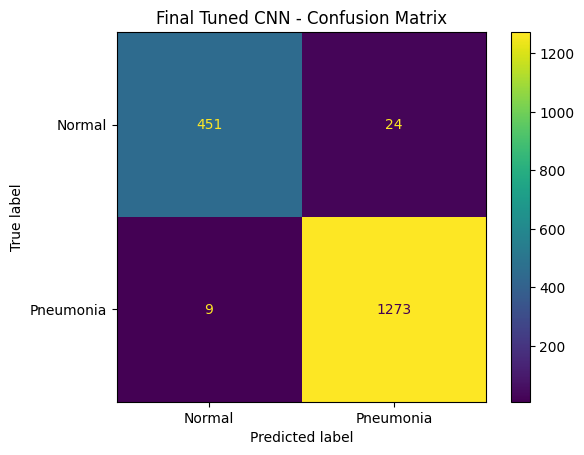

In [67]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot()

plt.title("Final Tuned CNN - Confusion Matrix")
plt.show()

In [68]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUROC"
    ],
    "Baseline CNN": [
        accuracy,
        precision,
        recall,
        f1,
        auroc
    ],
    "Tuned CNN": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_auroc
    ]
})

final_results

,Metric,Baseline CNN,Tuned CNN
0,Accuracy,0.981787,0.981218
1,Precision,0.992902,0.981496
2,Recall,0.982059,0.992980
3,F1-score,0.987451,0.987204
4,AUROC,0.998049,0.996996
